# Analyse finale méthodes d'estimation HybridIoT

Évaluation complète des deux méthodes d'estimation implémentées: historique (méthode 1, endogène non coopérative) et exogène (méthode 3, coopérative hétérogène), sur l'ensemble des 18 agents (6 stations × 3 types: température, humidité, pression).
Pour chaque agent et chaque timestamp à partir des 3/4 du dataset:
- estimation par historique
- estimation exogène (avec logging des collaborateurs sélectionnés)
- comparaison à la valeur réelle et à la baseline de persistance

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pickle

from hybridiot import MeteoDataset, Agent, Environment, Estimator

## 1. Setup: construction des agents avec pickle

La construction des 18 agents (chargement CSV + load_from_dataset) est coûteuse. On la fait une seule fois et on sauvegarde l'objet Environment complet dans un fichier pickle.

In [2]:
PICKLE_PATH = '../data/agents_toulouse_meteo_2020(35.000).pkl'
CSV_PATH    = '../data/toulouse_meteo_2020(35.000).csv'
DATA_TYPES  = ['temperature', 'humidite', 'pression']

if os.path.exists(PICKLE_PATH):
    print('Chargement depuis pickle...')
    with open(PICKLE_PATH, 'rb') as f:
        env = pickle.load(f)
    print(f'Chargé : {env}')
else:
    print('Construction des agents...')
    ds = MeteoDataset.from_csv(CSV_PATH)
    env = Environment(base_dataset=ds)

    for station in ds.sensors:
        for dtype in DATA_TYPES:
            agent = Agent(
                id        = station.id,
                position  = station.position,
                data_type = dtype,
                frequency = 15,
            )
            env.register_agent(agent)
            agent.load_from_dataset(ds)

    with open(PICKLE_PATH, 'wb') as f:
        pickle.dump(env, f)
    print(f'Sauvegardé : {env}')

print(f'\n{len(env.agents)} agents :')
for a in env.agents:
    n_valid = len([v for _, v in a.dataset if v is not None and not (isinstance(v, float) and np.isnan(v))])
    print(f'  {a.id}  [{a.data_type}]  {len(a.dataset)} entrées ({n_valid} valides)')

Construction des agents...
  Sampling frequency detected: 15 min
Sauvegardé : Environment(agents=18, base_dataset='toulouse_meteo_2020(35.000)')

18 agents :
  Castelginest Ecole  [temperature]  35136 entrées (34663 valides)
  Castelginest Ecole  [humidite]  35136 entrées (34694 valides)
  Castelginest Ecole  [pression]  35136 entrées (34694 valides)
  Colomiers Za Perget  [temperature]  35136 entrées (33436 valides)
  Colomiers Za Perget  [humidite]  35136 entrées (33439 valides)
  Colomiers Za Perget  [pression]  35136 entrées (33439 valides)
  Mondouzil Mairie  [temperature]  35136 entrées (34995 valides)
  Mondouzil Mairie  [humidite]  35136 entrées (35102 valides)
  Mondouzil Mairie  [pression]  35136 entrées (35102 valides)
  Toulouse Avenue De Grande Bretagne  [temperature]  35136 entrées (34563 valides)
  Toulouse Avenue De Grande Bretagne  [humidite]  35136 entrées (34568 valides)
  Toulouse Avenue De Grande Bretagne  [pression]  35136 entrées (34568 valides)
  Toulouse Basso 

## 2. Boucle de calcul

Pour chaque agent, on estime à chaque timestamp à partir des 3/4 du dataset. On sauvegarde les résultats dans un DataFrame pour l'analyse.
Cette cellule prend du temps (15 min pour l'historique, 1-2h pour l'exogène sur les 18 agents). Relancer le notebook après la première exécution charge les résultats depuis le pickle sans recalculer.

In [3]:
RESULTS_PICKLE = '../data/results_final_toulouse_meteo_2020(35.000).pkl'
COLLAB_RATIO   = 0.3   # 30% des collaborateurs

if os.path.exists(RESULTS_PICKLE):
    print('Chargement des résultats depuis pickle...')
    df = pd.read_pickle(RESULTS_PICKLE)
    print(f'Chargé : {len(df)} lignes')
else:
    results = []

    for agent_idx, agent in enumerate(env.agents):
        # Starting point: 3/4 of the dataset
        start_idx = (len(agent.dataset) * 3) // 4
        total = len(agent.dataset) - start_idx
        agent_label = f'{agent.id} [{agent.data_type}]'

        for i, idx in enumerate(range(start_idx, len(agent.dataset))):
            ts, real = agent.dataset[idx]

            # Skip NaN/None values (no ground truth)
            if real is None or (isinstance(real, float) and np.isnan(real)):
                continue

            # Method 1: history
            est_hist = agent.estimate_from_history(ts)

            # Method 3: exogenous
            est_exo = agent.estimate_exogenous(ts, collab_ratio=COLLAB_RATIO)

            # Persistence baseline
            valid_before = agent._get_valid_values(before=ts)
            persistence = valid_before[-1] if valid_before else None

            results.append({
                'timestamp':      ts,
                'station':        agent.id,
                'data_type':      agent.data_type,
                'real':           real,
                'est_history':    est_hist,
                'est_exogenous':  est_exo,
                'endogenous':     agent.last_endogenous,
                'persistence':    persistence,
                'collaborators':  agent.last_collaborators.copy(),
                'n_collab':       len(agent.last_collaborators),
            })

            # Progress
            if (i + 1) % 2000 == 0:
                print(f'  {agent_label}: {i+1}/{total}')

        print(f'[{agent_idx+1}/{len(env.agents)}] {agent_label} terminé')

    df = pd.DataFrame(results)
    df.to_pickle(RESULTS_PICKLE)
    print(f'\nSauvegardé : {len(df)} lignes')

  Castelginest Ecole [temperature]: 2000/8784
  Castelginest Ecole [temperature]: 4000/8784
  Castelginest Ecole [temperature]: 6000/8784
  Castelginest Ecole [temperature]: 8000/8784
[1/18] Castelginest Ecole [temperature] terminé
  Castelginest Ecole [humidite]: 2000/8784
  Castelginest Ecole [humidite]: 4000/8784
  Castelginest Ecole [humidite]: 6000/8784
  Castelginest Ecole [humidite]: 8000/8784
[2/18] Castelginest Ecole [humidite] terminé
  Castelginest Ecole [pression]: 2000/8784
  Castelginest Ecole [pression]: 4000/8784
  Castelginest Ecole [pression]: 6000/8784
  Castelginest Ecole [pression]: 8000/8784
[3/18] Castelginest Ecole [pression] terminé
  Colomiers Za Perget [temperature]: 2000/8784
  Colomiers Za Perget [temperature]: 4000/8784
  Colomiers Za Perget [temperature]: 6000/8784
[4/18] Colomiers Za Perget [temperature] terminé
  Colomiers Za Perget [humidite]: 2000/8784
  Colomiers Za Perget [humidite]: 4000/8784
  Colomiers Za Perget [humidite]: 6000/8784
[5/18] Colom

In [4]:
# Calcul des erreurs
df['err_history']     = (df['est_history']   - df['real']).abs()
df['err_exogenous']   = (df['est_exogenous'] - df['real']).abs()
df['err_persistence'] = (df['persistence']   - df['real']).abs()

# Estimation coopérative seule (le bin), obtenue par algèbre:
#   E_exo = (bin + E_end) / 2   =>   bin = 2*E_exo - E_end
# Permet de distinguer un apport reel des collaborateurs d'un simple
# effet d'amortissement du a la moyenne.
df['est_bin'] = 2 * df['est_exogenous'] - df['endogenous']
df['err_bin'] = (df['est_bin'] - df['real']).abs()

# Filtrer les lignes ou une estimation est None
df_hist = df.dropna(subset=['est_history'])
df_exo  = df.dropna(subset=['est_exogenous'])
print(f'Resultats : {len(df)} total, {len(df_hist)} avec historique, {len(df_exo)} avec exogene')
df.head()

Resultats : 148651 total, 148651 avec historique, 148651 avec exogene


,timestamp,station,data_type,real,est_history,est_exogenous,endogenous,persistence,collaborators,n_collab,err_history,err_exogenous,err_persistence,est_bin,err_bin
0,2020-10-01 12:00:00+00:00,Castelginest Ecole,temperature,18.000000,18.220240,18.926350,18.220240,17.799999,"[Mondouzil Mairie [pression], Toulouse Avenue ...",3,0.220240,0.926350,0.200001,19.632460,1.632460
1,2020-10-01 12:15:00+00:00,Castelginest Ecole,temperature,18.200001,18.539910,17.919380,18.539910,18.000000,"[Mondouzil Mairie [pression], Toulouse Avenue ...",3,0.339909,0.280620,0.200001,17.298851,0.901150
2,2020-10-01 12:30:00+00:00,Castelginest Ecole,temperature,18.200001,18.539928,18.706287,18.539928,18.200001,"[Toulouse Nakache Archive2019 [humidite], Mond...",3,0.339927,0.506287,0.000000,18.872647,0.672646
3,2020-10-01 12:45:00+00:00,Castelginest Ecole,temperature,18.200001,18.539600,18.369800,18.539600,18.200001,"[Mondouzil Mairie [pression], Toulouse Nakache...",3,0.339599,0.169800,0.000000,18.200001,0.000000
4,2020-10-01 13:00:00+00:00,Castelginest Ecole,temperature,18.000000,18.390079,18.295040,18.390079,18.200001,[Toulouse Avenue De Grande Bretagne [humidite]...,3,0.390079,0.295040,0.200001,18.200001,0.200001


## 3. Analyse methode historique
### 3.1 Statistiques globales par agent

MAE normalisee: Les trois types de donnees ont des echelles tres differentes
(temperature en degres C, humidite en %, pression en Pa autour de 101 000).
Comparer directement les MAE n'a pas de sens: on normalise par l'ecart-type des
valeurs reelles de chaque agent (nMAE = MAE / ecart-type), ce qui rend les
18 agents comparables entre eux.

In [5]:
# Ecart-type des valeurs reelles par agent, pour normaliser la MAE
std_real = df_hist.groupby(['station', 'data_type'])['real'].std().rename('std_real')

stats_hist = df_hist.groupby(['station', 'data_type']).agg(
    mae_history     = ('err_history',     'mean'),
    std_history     = ('err_history',     'std'),
    mae_persistence = ('err_persistence', 'mean'),
    n_estimations   = ('err_history',     'count'),
).join(std_real).reset_index()

stats_hist['nmae_history'] = stats_hist['mae_history'] / stats_hist['std_real']
stats_hist['nmae_persistence'] = stats_hist['mae_persistence'] / stats_hist['std_real']
stats_hist['agent'] = stats_hist['station'] + ' [' + stats_hist['data_type'] + ']'
stats_hist['improvement'] = (1 - stats_hist['mae_history'] / stats_hist['mae_persistence']) * 100
stats_hist = stats_hist.sort_values('nmae_history')

print(stats_hist[['agent', 'mae_history', 'nmae_history', 'nmae_persistence',
                  'improvement', 'n_estimations']].to_string(index=False))

                                           agent  mae_history  nmae_history  nmae_persistence  improvement  n_estimations
                 Toulouse Basso Cambo [pression]    25.397027      0.025870          0.014186   -82.356433           8207
         Toulouse Nakache Archive2019 [pression]    25.397027      0.025870          0.014186   -82.356433           8207
                  Colomiers Za Perget [pression]    25.213279      0.026767          0.014879   -79.891927           7092
              Toulouse Basso Cambo [temperature]     0.135098      0.029853          0.036926    19.153940           8205
      Toulouse Nakache Archive2019 [temperature]     0.135101      0.029853          0.036926    19.152492           8205
Toulouse Avenue De Grande Bretagne [temperature]     0.133623      0.029944          0.037061    19.201705           8489
                Castelginest Ecole [temperature]     0.154396      0.032449          0.041106    21.059267           8766
                     Mon

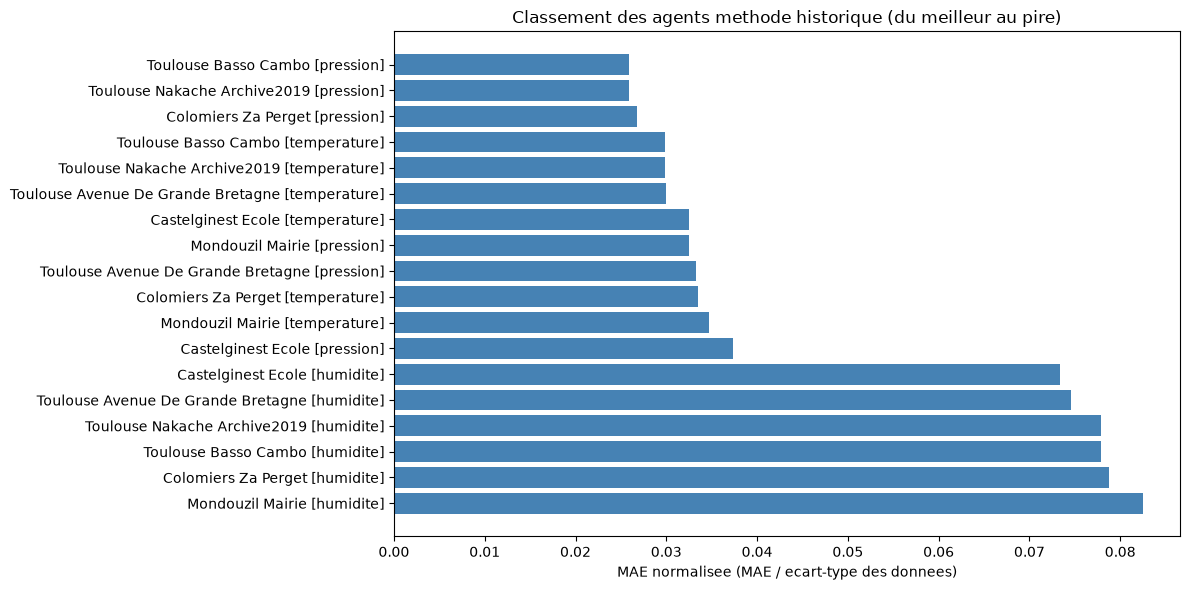

In [6]:
# Graphique a barres: classement des agents (MAE normalise, historique)
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(stats_hist['agent'], stats_hist['nmae_history'], color='steelblue')
ax.set_xlabel('MAE normalisee (MAE / ecart-type des donnees)')
ax.set_title('Classement des agents methode historique (du meilleur au pire)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 3.2 Série temporelle: meilleur vs pire agent

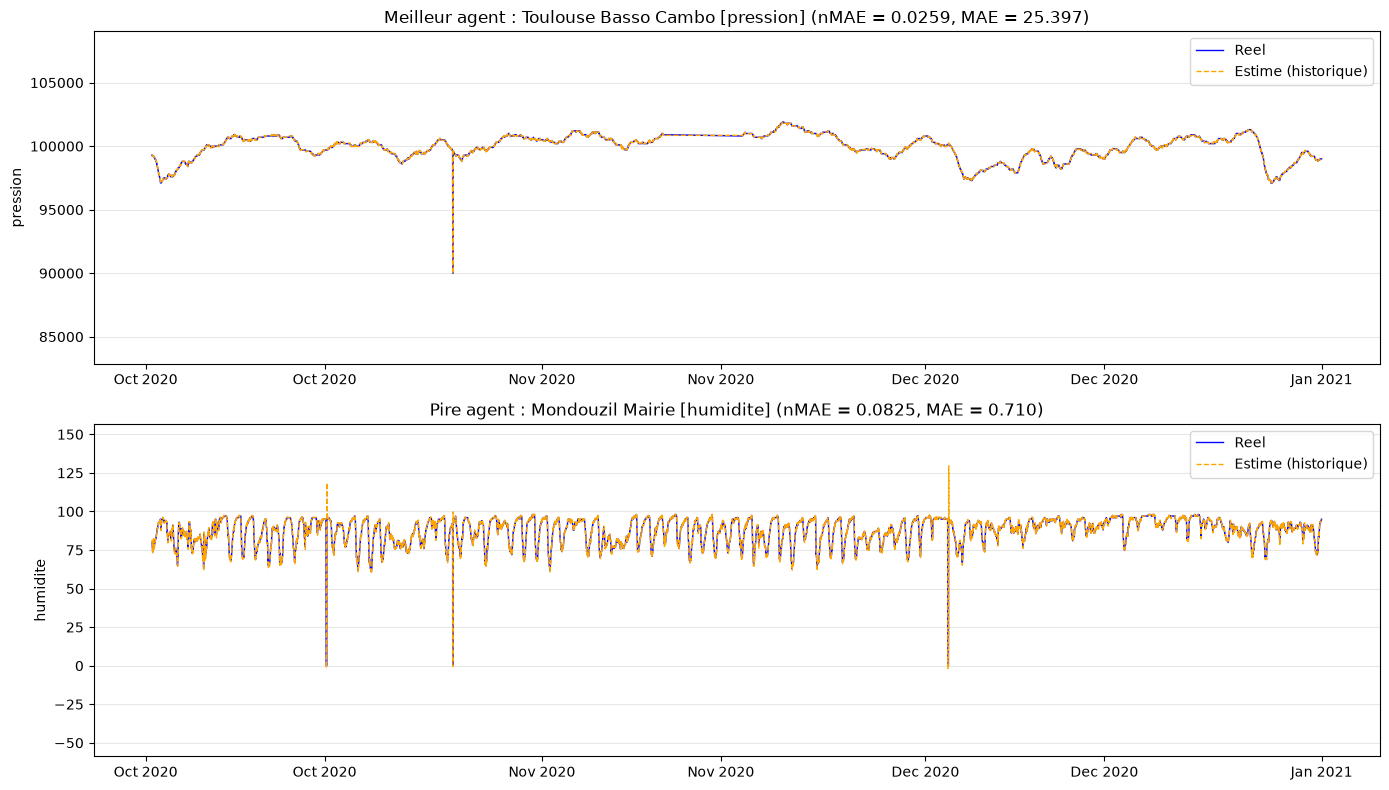

In [7]:
best_agent  = stats_hist.iloc[0]
worst_agent = stats_hist.iloc[-1]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

for ax, info, label in zip(axes, [best_agent, worst_agent], ['Meilleur', 'Pire']):
    subset = df_hist[(df_hist['station'] == info['station']) & (df_hist['data_type'] == info['data_type'])]
    ax.plot(subset['timestamp'], subset['real'], label='Reel', color='blue', linewidth=1)
    ax.plot(subset['timestamp'], subset['est_history'], label='Estime (historique)', color='orange', linewidth=1, linestyle='--')
    ax.set_title(f"{label} agent : {info['agent']} (nMAE = {info['nmae_history']:.4f}, MAE = {info['mae_history']:.3f})")
    ax.set_ylabel(info['data_type'])
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    # Echelle centree sur les valeurs reelles : une estimation aberrante
    # ecraserait sinon la courbe reelle sur une ligne plate.
    lo, hi = subset['real'].min(), subset['real'].max()
    marge = (hi - lo) * 0.6 if hi > lo else 1.0
    ax.set_ylim(lo - marge, hi + marge)

plt.tight_layout()
plt.show()

## 4. Analyse méthode exogène

### 4.1 Statistiques globales par agent

In [8]:
std_real_exo = df_exo.groupby(['station', 'data_type'])['real'].std().rename('std_real')

stats_exo = df_exo.groupby(['station', 'data_type']).agg(
    mae_exogenous   = ('err_exogenous',   'mean'),
    std_exogenous   = ('err_exogenous',   'std'),
    mae_history     = ('err_history',     'mean'),
    mae_persistence = ('err_persistence', 'mean'),
    mae_bin         = ('err_bin',         'mean'),   # cooperatif seul
    n_estimations   = ('err_exogenous',   'count'),
).join(std_real_exo).reset_index()

stats_exo['nmae_exogenous'] = stats_exo['mae_exogenous'] / stats_exo['std_real']
stats_exo['nmae_history']   = stats_exo['mae_history']   / stats_exo['std_real']
stats_exo['nmae_bin']       = stats_exo['mae_bin']       / stats_exo['std_real']
stats_exo['agent'] = stats_exo['station'] + ' [' + stats_exo['data_type'] + ']'
stats_exo['exo_vs_persistence'] = (1 - stats_exo['mae_exogenous'] / stats_exo['mae_persistence']) * 100
stats_exo['exo_vs_history']     = (1 - stats_exo['mae_exogenous'] / stats_exo['mae_history']) * 100
stats_exo = stats_exo.sort_values('nmae_exogenous')

print(stats_exo[['agent', 'mae_exogenous', 'nmae_exogenous', 'nmae_history',
                 'nmae_bin', 'exo_vs_history', 'n_estimations']].to_string(index=False))

                                           agent  mae_exogenous  nmae_exogenous  nmae_history  nmae_bin  exo_vs_history  n_estimations
                 Toulouse Basso Cambo [pression]      19.747389        0.020115      0.025870  0.014371       22.245275           8207
         Toulouse Nakache Archive2019 [pression]      19.747752        0.020115      0.025870  0.014370       22.243843           8207
                  Colomiers Za Perget [pression]      19.694897        0.020908      0.026767  0.015065       21.886808           7092
   Toulouse Avenue De Grande Bretagne [pression]      29.690544        0.023533      0.033316  0.013778       29.365152           8492
                     Mondouzil Mairie [pression]      28.188812        0.026491      0.032471  0.020519       18.415893           8783
                   Castelginest Ecole [pression]      33.577658        0.029498      0.037348  0.021721       21.018583           8783
      Toulouse Nakache Archive2019 [temperature]       

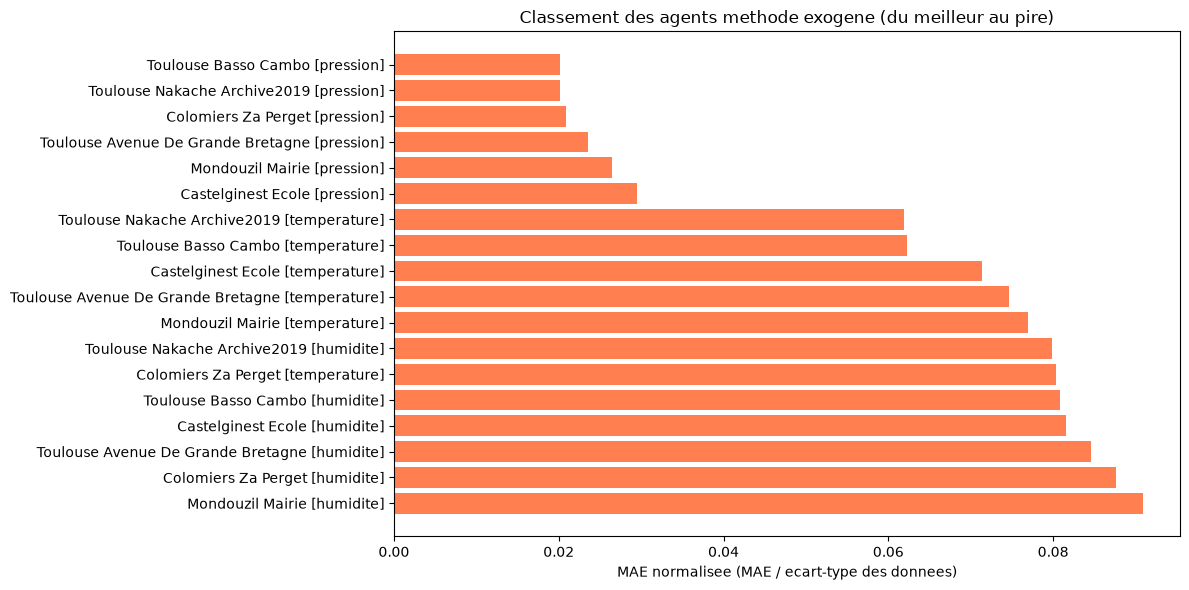

In [9]:
# Graphique a barres: classement des agents (MAE normalisee, exogene)
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(stats_exo['agent'], stats_exo['nmae_exogenous'], color='coral')
ax.set_xlabel('MAE normalisee (MAE / ecart-type des donnees)')
ax.set_title('Classement des agents methode exogene (du meilleur au pire)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

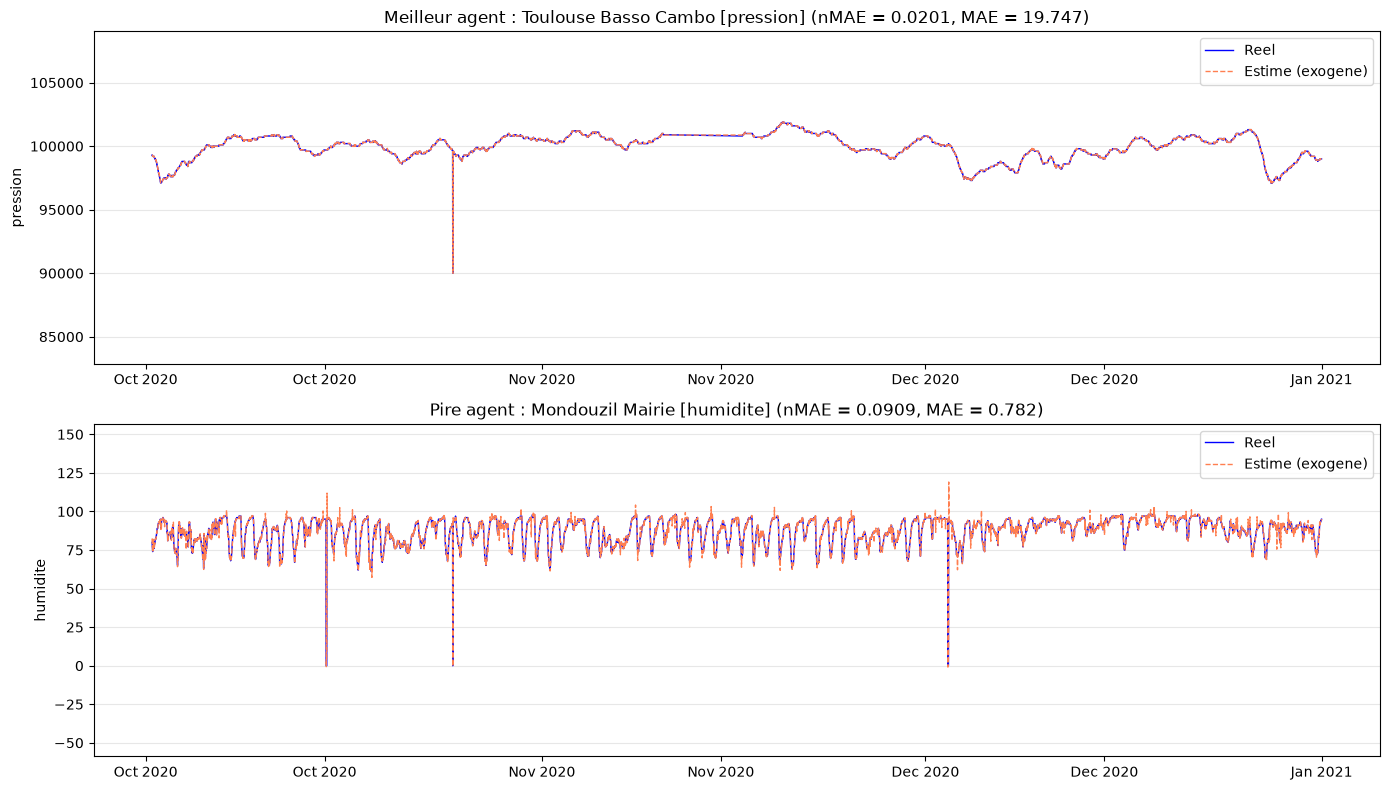

In [10]:
# Serie temporelle meilleur vs pire (exogene)
best_exo  = stats_exo.iloc[0]
worst_exo = stats_exo.iloc[-1]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

for ax, info, label in zip(axes, [best_exo, worst_exo], ['Meilleur', 'Pire']):
    subset = df_exo[(df_exo['station'] == info['station']) & (df_exo['data_type'] == info['data_type'])]
    ax.plot(subset['timestamp'], subset['real'], label='Reel', color='blue', linewidth=1)
    ax.plot(subset['timestamp'], subset['est_exogenous'], label='Estime (exogene)', color='coral', linewidth=1, linestyle='--')
    ax.set_title(f"{label} agent : {info['agent']} (nMAE = {info['nmae_exogenous']:.4f}, MAE = {info['mae_exogenous']:.3f})")
    ax.set_ylabel(info['data_type'])
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    lo, hi = subset['real'].min(), subset['real'].max()
    marge = (hi - lo) * 0.6 if hi > lo else 1.0
    ax.set_ylim(lo - marge, hi + marge)

plt.tight_layout()
plt.show()

## 5. Comparaison historique vs exogene vs persistance

### 5.1 Comparaison groupee par type de donnee

On ajoute ici l'erreur de l'estimation cooperative seule (bin), reconstruite par bin = 2*E_exo - E_end. Elle permet de tester si les collaborateurs apportent reellement de l'information:
- erreur du bin du meme ordre que l'endogene  ->  apport reel
- erreur du bin nettement superieure          ->  la coop. n'agit que comme amortisseur
  (la moyenne (bin + E_end)/2 ameliore une mauvaise estimation et degrade une bonne)

In [11]:
std_by_type = df_exo.groupby('data_type')['real'].std().rename('std_real')

compare = df_exo.groupby('data_type').agg(
    mae_persistence = ('err_persistence', 'mean'),
    mae_history     = ('err_history',     'mean'),
    mae_exogenous   = ('err_exogenous',   'mean'),
    mae_bin         = ('err_bin',         'mean'),
).join(std_by_type)

for c in ['mae_persistence', 'mae_history', 'mae_exogenous', 'mae_bin']:
    compare['n' + c] = compare[c] / compare['std_real']

compare = compare.reset_index()

print('MAE brutes (echelles non comparables entre types) :')
print(compare[['data_type', 'mae_persistence', 'mae_history', 'mae_exogenous', 'mae_bin']].to_string(index=False))
print()
print('MAE normalisees (comparables) :')
print(compare[['data_type', 'nmae_persistence', 'nmae_history', 'nmae_exogenous', 'nmae_bin']].to_string(index=False))

MAE brutes (echelles non comparables entre types) :
  data_type  mae_persistence  mae_history  mae_exogenous   mae_bin
   humidite         0.659390     0.682984       0.742644  0.887037
   pression        17.762892    32.876574      25.390199 17.931596
temperature         0.175797     0.143373       0.321439  0.560030

MAE normalisees (comparables) :
  data_type  nmae_persistence  nmae_history  nmae_exogenous  nmae_bin
   humidite          0.073816      0.076457        0.083136  0.099300
   pression          0.015800      0.029244        0.022585  0.015951
temperature          0.038715      0.031575        0.070789  0.123334


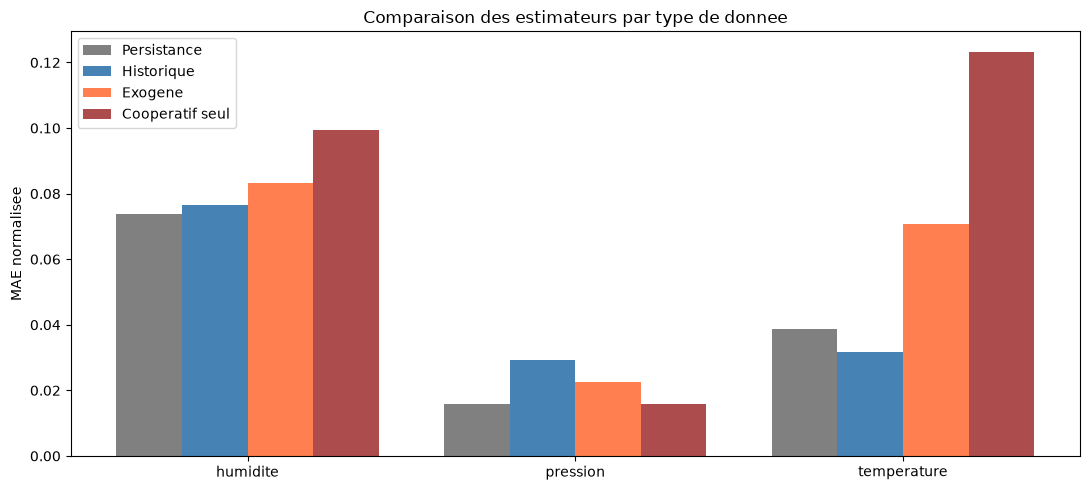

In [12]:
# Barres groupees: 4 estimateurs x 3 types de donnees (MAE normalisee)
x = np.arange(len(compare))
w = 0.2

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 1.5*w, compare['nmae_persistence'], w, label='Persistance',      color='gray')
ax.bar(x - 0.5*w, compare['nmae_history'],     w, label='Historique',       color='steelblue')
ax.bar(x + 0.5*w, compare['nmae_exogenous'],   w, label='Exogene',          color='coral')
ax.bar(x + 1.5*w, compare['nmae_bin'],         w, label='Cooperatif seul',  color='darkred', alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels(compare['data_type'])
ax.set_ylabel('MAE normalisee')
ax.set_title('Comparaison des estimateurs par type de donnee')
ax.legend()
plt.tight_layout()
plt.show()

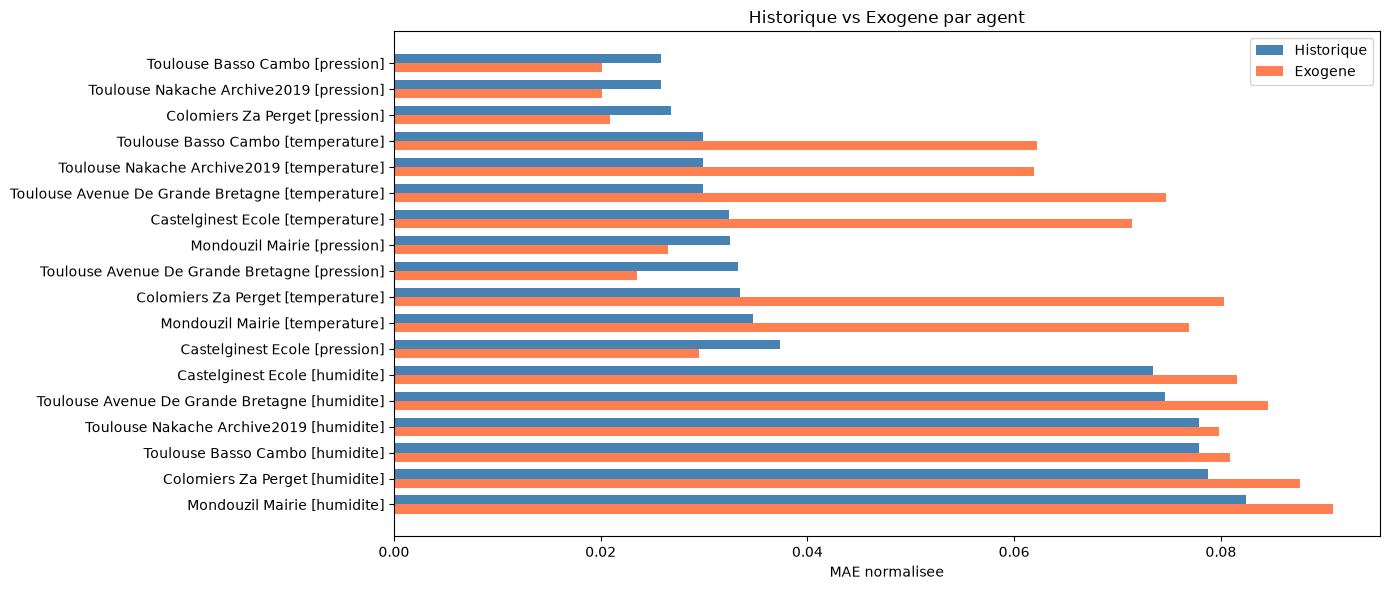

In [13]:
# Barres groupees par agent: historique vs exogene (MAE normalisee)
compare_agent = stats_exo[['agent', 'nmae_history', 'nmae_exogenous']].copy()
compare_agent = compare_agent.sort_values('nmae_history')

x = np.arange(len(compare_agent))
w = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
ax.barh(x - w/2, compare_agent['nmae_history'],   w, label='Historique', color='steelblue')
ax.barh(x + w/2, compare_agent['nmae_exogenous'], w, label='Exogene',    color='coral')
ax.set_yticks(x)
ax.set_yticklabels(compare_agent['agent'])
ax.set_xlabel('MAE normalisee')
ax.set_title('Historique vs Exogene par agent')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Analyse des collaborateurs

Quels collaborateurs contribuent le plus a la reduction de l'erreur pour chaque agent cible?

Les collaborateurs sont identifies par station [type]: plusieurs agents partagent le
meme identifiant de station, le type de donnee est donc necessaire pour les distinguer.

In [14]:
# Exploser la colonne collaborators: une ligne par collaborateur
df_collab = df_exo[df_exo['collaborators'].apply(len) > 0].copy()
df_collab = df_collab.explode('collaborators')

# MAE quand un collaborateur est présent, par agent cible
collab_impact = df_collab.groupby(['station', 'data_type', 'collaborators']).agg(
    mae_when_present = ('err_exogenous', 'mean'),
    times_selected   = ('err_exogenous', 'count'),
).reset_index()
collab_impact['agent'] = collab_impact['station'] + ' [' + collab_impact['data_type'] + ']'

# Top 5 collaborateurs les plus sélectionnés par agent
for agent_name in collab_impact['agent'].unique():
    subset = collab_impact[collab_impact['agent'] == agent_name].sort_values('times_selected', ascending=False)
    print(f'\n{agent_name} :')
    print(subset[['collaborators', 'mae_when_present', 'times_selected']].head(5).to_string(index=False))


Castelginest Ecole [humidite] :
                                   collaborators  mae_when_present  times_selected
   Toulouse Avenue De Grande Bretagne [pression]          0.844178            3324
Toulouse Avenue De Grande Bretagne [temperature]          0.733535            3259
         Toulouse Nakache Archive2019 [pression]          0.851436            2989
      Toulouse Nakache Archive2019 [temperature]          0.662422            2911
              Toulouse Basso Cambo [temperature]          0.773064            2567

Castelginest Ecole [pression] :
                                   collaborators  mae_when_present  times_selected
Toulouse Avenue De Grande Bretagne [temperature]         27.027231            3315
   Toulouse Avenue De Grande Bretagne [humidite]         27.737419            3282
      Toulouse Nakache Archive2019 [temperature]         37.927231            2968
         Toulouse Nakache Archive2019 [humidite]         31.180621            2935
              Toulous

In [ ]:
# Composition du trio en TYPES de donnees
def composition(collabs):
    types = sorted(c.split('[')[1].rstrip(']') for c in collabs)
    return ' + '.join(types)

df_exo['compo'] = df_exo['collaborators'].apply(composition)

std_t = df_exo.groupby('data_type')['real'].std().rename('std_real')
compo_stats = df_exo.groupby(['data_type', 'compo']).agg(
    mae      = ('err_exogenous', 'mean'),
    mae_hist = ('err_history',   'mean'),
    n        = ('err_exogenous', 'count'),
).join(std_t).reset_index()
compo_stats['nmae']         = compo_stats['mae'] / compo_stats['std_real']
compo_stats['gain_vs_hist'] = (1 - compo_stats['mae'] / compo_stats['mae_hist']) * 100

for dt in compo_stats['data_type'].unique():
    print(f'\nAgent cible : {dt}')
    sub = compo_stats[compo_stats['data_type'] == dt].sort_values('nmae')
    print(sub[['compo', 'nmae', 'gain_vs_hist', 'n']].to_string(index=False))


=== Agent cible : humidite ===
                                  compo     nmae  gain_vs_hist     n
temperature + temperature + temperature 0.073720      3.623004  3624
      pression + pression + temperature 0.073780      2.549216 21170
   pression + temperature + temperature 0.075035      2.811552 21051
         pression + pression + pression 0.191420   -150.422293  3719

=== Agent cible : pression ===
                                  compo     nmae  gain_vs_hist     n
temperature + temperature + temperature 0.018728     23.295074  3556
         humidite + humidite + humidite 0.019471     25.099830  3563
      humidite + humidite + temperature 0.021402     23.716511 21088
   humidite + temperature + temperature 0.024916     21.561708 21357

=== Agent cible : temperature ===
                         compo     nmae  gain_vs_hist     n
humidite + humidite + pression 0.050964    -60.610109 21229
humidite + humidite + humidite 0.051737    -64.920383  3572
humidite + pression + pression 

## 7. Exploration du ratio de collaborateurs

On teste différents ratios (10%, 30%, 50%, 100%) sur un échantillon de timestamps pour voir l'impact sur la MAE. Le ratio de la section 2 (30%) sert de référence.
Cette cellule est plus longue car on relance les estimations exogènes avec différents ratios. On utilise un sous-échantillon pour limiter le temps.

In [18]:
RATIO_PICKLE = '../data/results_ratio_exploration_toulouse_meteo_2020(35.000).pkl'
RATIOS = [0.1, 0.3, 0.5, 1.0]
SAMPLE_STEP = 10  # 1 timestamp sur 10

if os.path.exists(RATIO_PICKLE):
    print('Chargement des resultats ratio...')
    df_ratio = pd.read_pickle(RATIO_PICKLE)
else:
    ratio_results = []

    for agent_idx, agent in enumerate(env.agents):
        start_idx = (len(agent.dataset) * 3) // 4
        agent_label = f'{agent.id} [{agent.data_type}]'

        for idx in range(start_idx, len(agent.dataset), SAMPLE_STEP):
            ts, real = agent.dataset[idx]
            if real is None or (isinstance(real, float) and np.isnan(real)):
                continue

            for ratio in RATIOS:
                est = agent.estimate_exogenous(ts, collab_ratio=ratio)
                if est is None:
                    continue

                ratio_results.append({
                    'station':   agent.id,
                    'data_type': agent.data_type,
                    'ratio':     ratio,
                    'real':      real,
                    'estimate':  est,
                    'error':     abs(est - real),
                })

        print(f'[{agent_idx+1}/{len(env.agents)}] {agent_label} termine')

    df_ratio = pd.DataFrame(ratio_results)
    df_ratio.to_pickle(RATIO_PICKLE)
    print(f'Sauvegarde : {len(df_ratio)} lignes')

# Normalisation par l'ecart-type des valeurs reelles de chaque type
std_ratio = df_ratio.groupby('data_type')['real'].std()
df_ratio['nerror'] = df_ratio['error'] / df_ratio['data_type'].map(std_ratio)

[1/18] Castelginest Ecole [temperature] termine
[2/18] Castelginest Ecole [humidite] termine
[3/18] Castelginest Ecole [pression] termine
[4/18] Colomiers Za Perget [temperature] termine
[5/18] Colomiers Za Perget [humidite] termine
[6/18] Colomiers Za Perget [pression] termine
[7/18] Mondouzil Mairie [temperature] termine
[8/18] Mondouzil Mairie [humidite] termine
[9/18] Mondouzil Mairie [pression] termine
[10/18] Toulouse Avenue De Grande Bretagne [temperature] termine
[11/18] Toulouse Avenue De Grande Bretagne [humidite] termine
[12/18] Toulouse Avenue De Grande Bretagne [pression] termine
[13/18] Toulouse Basso Cambo [temperature] termine
[14/18] Toulouse Basso Cambo [humidite] termine
[15/18] Toulouse Basso Cambo [pression] termine
[16/18] Toulouse Nakache Archive2019 [temperature] termine
[17/18] Toulouse Nakache Archive2019 [humidite] termine
[18/18] Toulouse Nakache Archive2019 [pression] termine
Sauvegarde : 59504 lignes


In [19]:
# MAE par ratio (global, normalisee)
ratio_stats = df_ratio.groupby('ratio').agg(
    mae   = ('error',  'mean'),
    nmae  = ('nerror', 'mean'),
    nstd  = ('nerror', 'std'),
    n     = ('error',  'count'),
).reset_index()
print(ratio_stats.to_string(index=False))

 ratio       mae     nmae     nstd     n
   0.1 10.149645 0.320748 2.990075 14876
   0.3  8.631852 0.054538 0.204075 14876
   0.5  8.595844 0.047656 0.187322 14876
   1.0  8.611556 0.048049 0.187099 14876


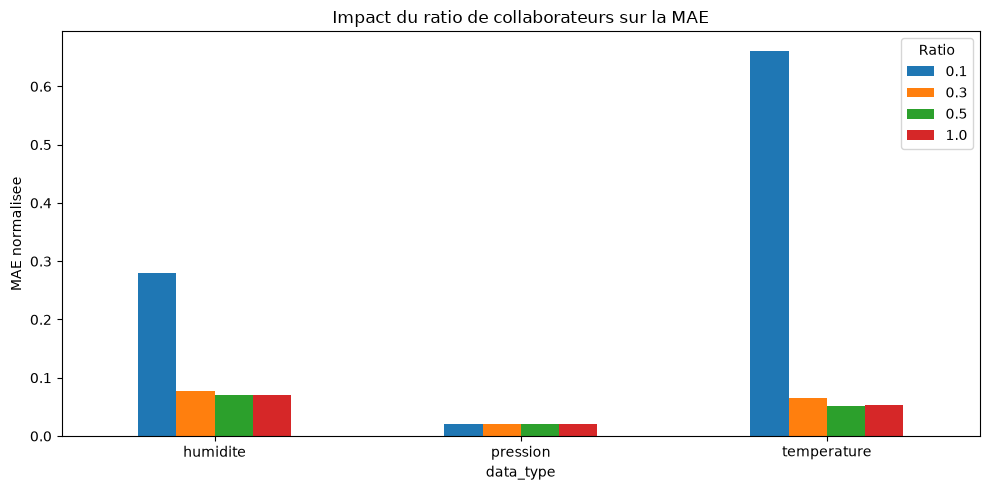

In [20]:
# MAE normalisee par ratio et par type de donnee
ratio_by_type = df_ratio.groupby(['data_type', 'ratio'])['nerror'].mean().unstack('ratio')

fig, ax = plt.subplots(figsize=(10, 5))
ratio_by_type.plot(kind='bar', ax=ax)
ax.set_ylabel('MAE normalisee')
ax.set_title('Impact du ratio de collaborateurs sur la MAE')
ax.set_xticklabels(ratio_by_type.index, rotation=0)
ax.legend(title='Ratio')
plt.tight_layout()
plt.show()

In [ ]:
# Sauvegarde robuste (independante de la version de pandas)
df.to_csv('../data/results_final.csv', index=False)
df_ratio.to_csv('../data/results_ratio.csv', index=False)